<a href="https://colab.research.google.com/github/seifahmed2004/Respiratory-and-cough-sound-classifier/blob/main/Respiratory_and_cough_sound_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [39]:
!pip install librosa

In [40]:
import pandas as pd
import librosa as sr
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import io
import zipfile

In [41]:
import librosa
import os
import zipfile
import io

# Using the newly repaired dataset ZIP file
zip_path = '/content/repaired_dataset.zip'

if not os.path.exists(zip_path):
    print(f"Error: {zip_path} does not exist.")
else:
    try:
        with zipfile.ZipFile(zip_path, 'r') as zf:
            namelist = zf.namelist()
            print(f"ZIP opened successfully! Total files inside: {len(namelist)}")

            # Search for any audio files (specifically webm or ogg which exist in this dataset)
            audio_files = [f for f in namelist if f.endswith(('.webm', '.ogg', '.wav', '.mp3'))]

            if audio_files:
                target_file = audio_files[0]
                print(f"\nFound audio files! Loading the first one: '{target_file}'...")

                with zf.open(target_file) as audio_file:
                    audio_bytes = io.BytesIO(audio_file.read())
                    # librosa can read ogg/webm if ffmpeg/soundfile are configured in the environment
                    y, sr_rate = librosa.load(audio_bytes, sr=None)
                    print(f"\nSuccessfully loaded!")
                    print(f"Loaded audio shape: {y.shape}")
                    print(f"Sample rate: {sr_rate} Hz")
            else:
                print("\nNo audio files (.webm, .ogg, etc.) found in the repaired ZIP archive.")

    except Exception as e:
        print(f"Failed to read the repaired ZIP file: {e}")

ZIP opened successfully! Total files inside: 21936

Found audio files! Loading the first one: 'public_dataset/00039425-7f3a-42aa-ac13-834aaa2b6b92.webm'...
Failed to read the repaired ZIP file: Error opening <_io.BytesIO object at 0x7976bdb59580>: Format not recognised.


In [42]:
!echo "=== Testing archive with system unzip ==="
!unzip -t /content/public_dataset.zip | head -n 30

!echo "\n=== Attempting to list contents using system unzip ==="
!unzip -l /content/public_dataset.zip | head -n 20

=== Testing archive with system unzip ===
unzip:  cannot find or open /content/public_dataset.zip, /content/public_dataset.zip.zip or /content/public_dataset.zip.ZIP.
unzip:  cannot find or open /content/public_dataset.zip, /content/public_dataset.zip.zip or /content/public_dataset.zip.ZIP.
\n=== Attempting to list contents using system unzip ===
unzip:  cannot find or open /content/public_dataset.zip, /content/public_dataset.zip.zip or /content/public_dataset.zip.ZIP.


In [43]:
!echo "=== Attempting to repair the ZIP file using system zip ==="
!zip -F /content/public_dataset.zip --out /content/repaired_dataset.zip || zip -FF /content/public_dataset.zip --out /content/repaired_dataset.zip

=== Attempting to repair the ZIP file using system zip ===
Fix archive (-F) - assume mostly intact archive
	zip warning: No .zip file found
        (If all you have are splits (.z01, .z02, ...) and no .zip, try -FF)
zip I/O error: No such file or directory
zip error: File not found or no read permission (/content/public_dataset.zip)
Fix archive (-FF) - salvage what can
	zip warning: could not open input archive: /content/public_dataset.zip
Scanning for entries...


Could not find:
  /content/public_dataset.z01

Hit c      (change path to where this split file is)
    s      (skip this split)
    q      (abort archive - quit)
    e      (end this archive - no more splits)
    z      (look for .zip split - the last split)
 or ENTER  (try reading this split again): ENTER
	zip warning: user ended reading - closing archive
	zip warning: zip file empty


In [44]:
import os
import zipfile

repaired_path = '/content/repaired_dataset.zip'
if os.path.exists(repaired_path):
    print(f"Repaired file size: {os.path.getsize(repaired_path)} bytes")
    try:
        with zipfile.ZipFile(repaired_path, 'r') as zf:
            names = zf.namelist()
            print(f"Successfully opened repaired ZIP! Found {len(names)} files.")
            print("Sample files inside:")
            for name in names[:10]:
                print(f" - {name}")
    except Exception as e:
        print(f"Could not read repaired file: {e}")
else:
    print("Repair failed or output file was not created.")

Repaired file size: 22 bytes
Successfully opened repaired ZIP! Found 0 files.
Sample files inside:


In [45]:
import os, json, random, shutil, subprocess, warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np, pandas as pd, librosa
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             confusion_matrix, roc_curve)
warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
DATA_DIR = Path("/content/public_dataset")
OUT_DIR = Path("/content/processed")
TASK = "status"            # "status" (self-reported, large) or "expert" (physician labels, small)
MIN_COUGH_PROB = 0.8
MAX_PER_CLASS = None        # set to None for the full dataset (use 300 first as a quick test)
SEED = 42
SR, DURATION, N_FFT, HOP, N_MELS = 16000, 5.0, 1024, 256, 64
# ----------------------------------------

def load_audio(path, sr=SR, duration=DURATION, trim_db=30):
    y, _ = librosa.load(path, sr=sr, mono=True)
    if len(y):
        y, _ = librosa.effects.trim(y, top_db=trim_db)
    n = int(sr * duration)
    if len(y) == 0:
        return np.zeros(n, dtype=np.float32)
    peak = np.max(np.abs(y))
    if peak > 0:
        y = y / peak
    y = np.pad(y, (0, n - len(y))) if len(y) < n else y[:n]
    return y.astype(np.float32)

def _stats(m):
    return np.concatenate([m.mean(axis=1), m.std(axis=1)])

def handcrafted_features(y, sr=SR):
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20, n_fft=N_FFT, hop_length=HOP)
    d1, d2 = librosa.feature.delta(mfcc), librosa.feature.delta(mfcc, order=2)
    spec = [
        librosa.feature.zero_crossing_rate(y, hop_length=HOP),
        librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP),
        librosa.feature.spectral_bandwidth(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP),
        librosa.feature.spectral_rolloff(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP),
        librosa.feature.rms(y=y, frame_length=N_FFT, hop_length=HOP),
        librosa.feature.spectral_flatness(y=y, n_fft=N_FFT, hop_length=HOP),
    ]
    f = np.concatenate([_stats(mfcc), _stats(d1), _stats(d2)] + [_stats(s) for s in spec])
    return np.nan_to_num(f).astype(np.float32)

def log_mel(y, sr=SR):
    m = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP,
                                       n_mels=N_MELS, fmin=50, fmax=sr // 2)
    return librosa.power_to_db(m, ref=np.max).astype(np.float32)

def extract_hand(path): return handcrafted_features(load_audio(path))
def extract_mel(path):  return log_mel(load_audio(path))

In [46]:
EPS = 1e-9

def compute_metrics(y_true, y_prob, thr=0.5):
    y_true = np.asarray(y_true)
    y_pred = (np.asarray(y_prob) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens, spec, prec = tp / (tp + fn + EPS), tn / (tn + fp + EPS), tp / (tp + fp + EPS)
    return {"threshold": float(thr), "roc_auc": float(roc_auc_score(y_true, y_prob)),
            "pr_auc": float(average_precision_score(y_true, y_prob)),
            "sensitivity_recall": float(sens), "specificity": float(spec),
            "precision": float(prec), "f1": float(2 * prec * sens / (prec + sens + EPS)),
            "balanced_accuracy": float((sens + spec) / 2),
            "accuracy": float((tp + tn) / len(y_true)),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def youden_threshold(y_true, y_prob):
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    j = tpr - fpr
    j[~np.isfinite(thr)] = -1
    return float(thr[int(np.argmax(j))])

def bootstrap_auc_ci(y_true, y_prob, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, y_prob = np.asarray(y_true), np.asarray(y_prob)
    aucs = []
    for _ in range(n):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) > 1:
            aucs.append(roc_auc_score(y_true[idx], y_prob[idx]))
    return float(np.percentile(aucs, 2.5)), float(np.percentile(aucs, 97.5))

def report(name, y_val, p_val, y_test, p_test, out_dir):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    thr = youden_threshold(y_val, p_val)          # threshold chosen on validation only
    tuned, default = compute_metrics(y_test, p_test, thr), compute_metrics(y_test, p_test, 0.5)
    lo, hi = bootstrap_auc_ci(y_test, p_test)
    result = {"model": name, "test_at_val_threshold": tuned, "test_at_0.5": default,
              "test_auc_95ci": [lo, hi]}
    (out_dir / f"{name}_metrics.json").write_text(json.dumps(result, indent=2))

    fig, ax = plt.subplots(1, 2, figsize=(9, 4))
    fpr, tpr, _ = roc_curve(y_test, p_test)
    ax[0].plot(fpr, tpr, label=f"AUC = {tuned['roc_auc']:.3f}")
    ax[0].plot([0, 1], [0, 1], "--", color="gray")
    ax[0].set(xlabel="1 - Specificity", ylabel="Sensitivity", title=f"{name} ROC (test)")
    ax[0].legend(loc="lower right")
    cm = np.array([[tuned["tn"], tuned["fp"]], [tuned["fn"], tuned["tp"]]])
    ax[1].imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax[1].text(j, i, str(v), ha="center", va="center")
    ax[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Healthy", "Unwell"],
              yticklabels=["Healthy", "Unwell"], xlabel="Predicted", ylabel="True",
              title=f"Confusion @ thr={thr:.2f}")
    plt.tight_layout(); plt.savefig(out_dir / f"{name}_plots.png", dpi=150); plt.show()

    print(f"[{name}] test AUC {tuned['roc_auc']:.3f} (95% CI {lo:.3f}-{hi:.3f}) | "
          f"sensitivity {tuned['sensitivity_recall']:.3f} | specificity {tuned['specificity']:.3f} | "
          f"F1 {tuned['f1']:.3f} | threshold {thr:.3f}")
    return result

In [47]:
!ls -lh /content/*.zip
!file /content/public_dataset.zip
!ls /content/public_dataset | head
!find /content -maxdepth 3 -iname "*.csv" | head
!find /content/public_dataset -type f | head -5
!find /content/public_dataset -type f | wc -l

-rw-r--r-- 1 root root 2.2G Nov 24 20:23 /content/public_dataset_v3.zip
-rw------- 1 root root   22 Nov 24 20:46 /content/repaired_dataset.zip
/content/public_dataset.zip: cannot open `/content/public_dataset.zip' (No such file or directory)
coughvid_20211012
/content/processed/manifest.csv
/content/public_dataset/coughvid_20211012/metadata_compiled.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/mnist_test.csv
/content/sample_data/california_housing_train.csv
/content/public_dataset/coughvid_20211012/00014dcc-0f06-4c27-8c7b-737b18a2cf4c.json
/content/public_dataset/coughvid_20211012/00014dcc-0f06-4c27-8c7b-737b18a2cf4c.webm
/content/public_dataset/coughvid_20211012/00039425-7f3a-42aa-ac13-834aaa2b6b92.json
/content/public_dataset/coughvid_20211012/00039425-7f3a-42aa-ac13-834aaa2b6b92.webm
/content/public_dataset/coughvid_20211012/0007c6f1-5441-40e6-9aaf-a761d8f2da3b.json
68869


In [48]:
!rm -rf /content/public_dataset /content/public_dataset*.zip
!wget --show-progress -O /content/public_dataset_v3.zip "https://zenodo.org/records/7024894/files/public_dataset_v3.zip?download=1"
!unzip -o /content/public_dataset_v3.zip -d /content/public_dataset | tail -3
!find /content/public_dataset -iname "metadata_compiled.csv"

--2026-11-24 20:46:52--  https://zenodo.org/records/7024894/files/public_dataset_v3.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.45.63, 188.185.40.132, 188.185.47.192, ...
Connecting to zenodo.org (zenodo.org)|188.185.45.63|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2297542075 (2.1G) [application/octet-stream]
Saving to: ‘/content/public_dataset_v3.zip’

/content/public_dat 100%[===================>]   2.14G  12.4MB/s    in 2m 58s  

2026-11-24 20:49:51 (12.3 MB/s) - ‘/content/public_dataset_v3.zip’ saved [2297542075/2297542075]

  inflating: /content/public_dataset/coughvid_20211012/fffd1834-6cf2-4782-bb30-04c31b46a1fe.json  
  inflating: /content/public_dataset/coughvid_20211012/fffd1834-6cf2-4782-bb30-04c31b46a1fe.wav  
  inflating: /content/public_dataset/coughvid_20211012/metadata_compiled.csv  
/content/public_dataset/coughvid_20211012/metadata_compiled.csv


In [49]:
!unzip -o /content/public_dataset_v3.zip -d /content/public_dataset | tail -3
!find /content/public_dataset -iname "metadata_compiled.csv"

  inflating: /content/public_dataset/coughvid_20211012/fffd1834-6cf2-4782-bb30-04c31b46a1fe.json  
  inflating: /content/public_dataset/coughvid_20211012/fffd1834-6cf2-4782-bb30-04c31b46a1fe.wav  
  inflating: /content/public_dataset/coughvid_20211012/metadata_compiled.csv  
/content/public_dataset/coughvid_20211012/metadata_compiled.csv


In [50]:
found = list(DATA_DIR.rglob("metadata_compiled.csv"))
assert found, f"metadata_compiled.csv not found under {DATA_DIR}. Contents: {[p.name for p in DATA_DIR.glob('*')][:10]}"
meta_path = found[0]

In [51]:
AUDIO_EXTS = {".webm", ".ogg", ".wav", ".mp3", ".m4a", ".flac"}

def to_wav(src, dst):
    if dst.exists():
        return True
    dst.parent.mkdir(parents=True, exist_ok=True)
    r = subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(src),
                        "-ac", "1", "-ar", str(SR), str(dst)], capture_output=True)
    return r.returncode == 0 and dst.exists()

meta_path = next(DATA_DIR.rglob("metadata_compiled.csv"))
df = pd.read_csv(meta_path)
df["cough_detected"] = pd.to_numeric(df["cough_detected"], errors="coerce")
df = df[df["cough_detected"] >= MIN_COUGH_PROB]

if TASK == "status":
    df = df[df["status"].isin(["healthy", "symptomatic", "COVID-19"])].copy()
    df["label_name"] = df["status"]
else:
    diag_cols = [c for c in df.columns if c.lower().startswith("diagnosis")]
    def vote(row):
        v = [x for x in row[diag_cols] if isinstance(x, str) and x.strip()]
        return Counter(v).most_common(1)[0][0] if v else None
    df = df.copy(); df["label_name"] = df.apply(vote, axis=1)
    df = df[df["label_name"].notna()].copy()
df["label"] = (~df["label_name"].isin({"healthy", "healthy_cough"})).astype(int)  # 0 healthy, 1 unwell

audio = {p.stem: p for p in DATA_DIR.rglob("*") if p.suffix.lower() in AUDIO_EXTS}
df["src"] = df["uuid"].map(audio)
df = df[df["src"].notna()].copy()
if MAX_PER_CLASS:
    df = pd.concat([g.sample(min(len(g), MAX_PER_CLASS), random_state=SEED) for _, g in df.groupby("label")])

wav_dir = OUT_DIR / "wav"
jobs = [(s, wav_dir / f"{u}.wav") for u, s in zip(df["uuid"], df["src"])]
with ThreadPoolExecutor(max_workers=os.cpu_count() or 4) as ex:
    ok = list(tqdm(ex.map(lambda a: to_wav(*a), jobs), total=len(jobs), desc="converting"))
df = df[np.array(ok, dtype=bool)].copy()
df["wav_path"] = [str(wav_dir / f"{u}.wav") for u in df["uuid"]]

trainval, test = train_test_split(df, test_size=0.15, stratify=df["label"], random_state=SEED)
train, val = train_test_split(trainval, test_size=0.1765, stratify=trainval["label"], random_state=SEED)
df.loc[train.index, "split"], df.loc[val.index, "split"], df.loc[test.index, "split"] = "train", "val", "test"
df.to_csv(OUT_DIR / "manifest.csv", index=False)

print(df.groupby(["split", "label"]).size().unstack(fill_value=0))
print(df["label_name"].value_counts())

converting:   0%|          | 0/13535 [00:00<?, ?it/s]

label     0     1
split            
test   1520   511
train  7092  2381
val    1520   511
label_name
healthy        10132
symptomatic     2683
COVID-19         720
Name: count, dtype: int64


features train:   0%|          | 0/9473 [00:00<?, ?it/s]

features val:   0%|          | 0/2031 [00:00<?, ?it/s]

features test:   0%|          | 0/2031 [00:00<?, ?it/s]

Best SVM params: {'svc__C': 0.5, 'svc__gamma': 0.003} | CV AUC: 0.59


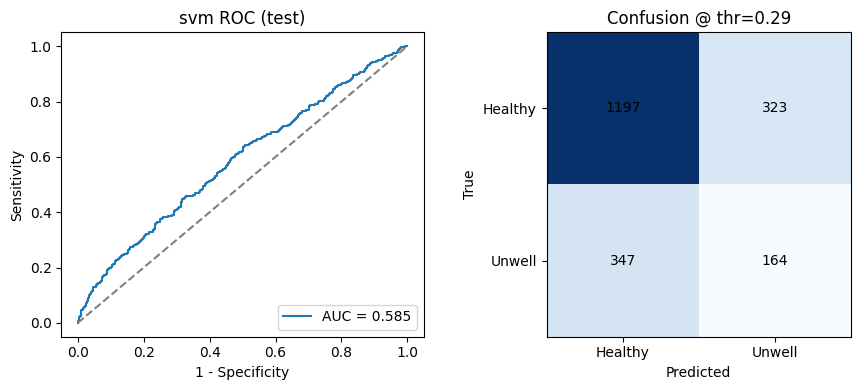

[svm] test AUC 0.585 (95% CI 0.555-0.612) | sensitivity 0.321 | specificity 0.787 | F1 0.329 | threshold 0.287


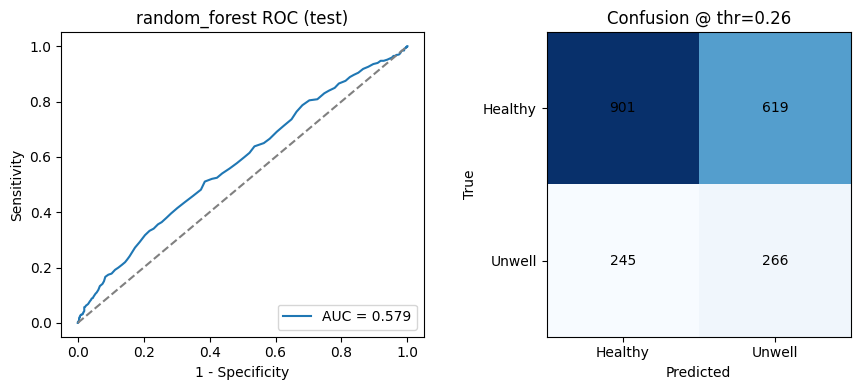

[random_forest] test AUC 0.579 (95% CI 0.549-0.608) | sensitivity 0.521 | specificity 0.593 | F1 0.381 | threshold 0.255


In [52]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

parts = {s: df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
y = {s: p["label"].values for s, p in parts.items()}

Xh = {s: np.vstack(Parallel(n_jobs=-1)(delayed(extract_hand)(p) for p in tqdm(parts[s]["wav_path"], desc=f"features {s}")))
      for s in parts}

grid = GridSearchCV(
    make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced")),
    {"svc__C": [0.5, 1, 5, 10], "svc__gamma": ["scale", 0.01, 0.003]},
    scoring="roc_auc", cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=-1)
grid.fit(Xh["train"], y["train"])
best = grid.best_params_
print("Best SVM params:", best, "| CV AUC:", round(grid.best_score_, 3))

svm = make_pipeline(StandardScaler(), CalibratedClassifierCV(
    SVC(kernel="rbf", class_weight="balanced", C=best["svc__C"], gamma=best["svc__gamma"]),
    method="sigmoid", cv=5)).fit(Xh["train"], y["train"])
rf = RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=SEED).fit(Xh["train"], y["train"])

results = {}
for name, model in {"svm": svm, "random_forest": rf}.items():
    results[name] = report(name, y["val"], model.predict_proba(Xh["val"])[:, 1],
                           y["test"], model.predict_proba(Xh["test"])[:, 1], "/content/results/baseline")

In [53]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import roc_auc_score

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

class SpecDataset(Dataset):
    def __init__(self, X, y, mean, std, augment=False):
        self.X, self.y, self.mean, self.std, self.augment = X, y, mean, std, augment
    def __len__(self): return len(self.X)
    def _augment(self, x):
        x = x.copy(); M, T = x.shape
        x = np.roll(x, np.random.randint(-T // 10, T // 10 + 1), axis=1)   # time shift
        for _ in range(2):                                                   # SpecAugment masks
            f = np.random.randint(0, 9);  f0 = np.random.randint(0, M - f + 1); x[f0:f0 + f, :] = 0
            t = np.random.randint(0, 31); t0 = np.random.randint(0, T - t + 1); x[:, t0:t0 + t] = 0
        return x
    def __getitem__(self, i):
        x = (self.X[i] - self.mean) / self.std
        if self.augment: x = self._augment(x)
        return torch.from_numpy(x).unsqueeze(0).float(), torch.tensor(float(self.y[i]))

def conv_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                         nn.MaxPool2d(2))

class CoughCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(conv_block(1, 16), conv_block(16, 32), conv_block(32, 64), conv_block(64, 128))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 1))
    def forward(self, x): return self.head(self.features(x)).squeeze(1)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    return np.concatenate([torch.sigmoid(model(x.to(device))).cpu().numpy() for x, _ in loader])

def grad_cam(model, x):
    model.eval()
    fmap = model.features(x)
    grads = torch.autograd.grad(model.head(fmap).sum(), fmap)[0]
    cam = F.relu((grads.mean(dim=(2, 3), keepdim=True) * fmap).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
    cam = cam - cam.min()
    return (cam / (cam.max() + 1e-8)).detach()

Device: cuda


log-mel train:   0%|          | 0/9473 [00:00<?, ?it/s]

log-mel val:   0%|          | 0/2031 [00:00<?, ?it/s]

log-mel test:   0%|          | 0/2031 [00:00<?, ?it/s]

epoch 01 | loss 1.0475 | val AUC 0.5643
epoch 02 | loss 1.0443 | val AUC 0.4726
epoch 03 | loss 1.0430 | val AUC 0.5650
epoch 04 | loss 1.0427 | val AUC 0.5638
epoch 05 | loss 1.0423 | val AUC 0.5692
epoch 06 | loss 1.0416 | val AUC 0.4676
epoch 07 | loss 1.0416 | val AUC 0.5713
epoch 08 | loss 1.0412 | val AUC 0.4467
epoch 09 | loss 1.0393 | val AUC 0.5691
epoch 10 | loss 1.0393 | val AUC 0.5567
epoch 11 | loss 1.0395 | val AUC 0.5782
epoch 12 | loss 1.0393 | val AUC 0.5745
epoch 13 | loss 1.0407 | val AUC 0.5750
epoch 14 | loss 1.0401 | val AUC 0.5747
epoch 15 | loss 1.0389 | val AUC 0.5732
epoch 16 | loss 1.0365 | val AUC 0.5895
epoch 17 | loss 1.0355 | val AUC 0.5778
epoch 18 | loss 1.0367 | val AUC 0.5908
epoch 19 | loss 1.0349 | val AUC 0.5943
epoch 20 | loss 1.0328 | val AUC 0.6056
epoch 21 | loss 1.0325 | val AUC 0.6032
epoch 22 | loss 1.0308 | val AUC 0.6059
epoch 23 | loss 1.0305 | val AUC 0.6077
epoch 24 | loss 1.0303 | val AUC 0.6145
epoch 25 | loss 1.0273 | val AUC 0.5944


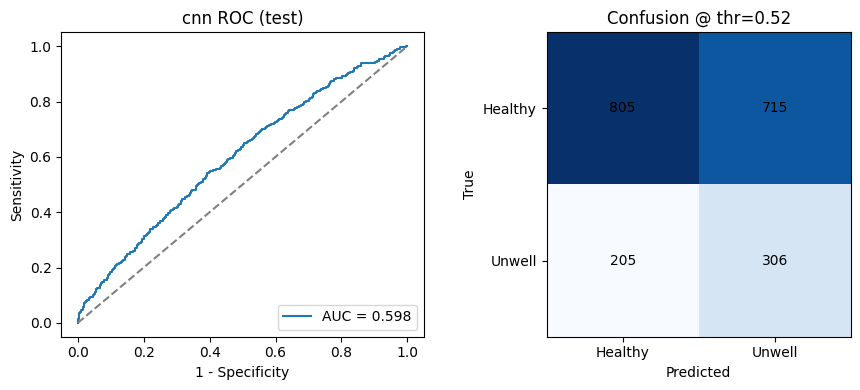

[cnn] test AUC 0.598 (95% CI 0.568-0.624) | sensitivity 0.599 | specificity 0.530 | F1 0.399 | threshold 0.517


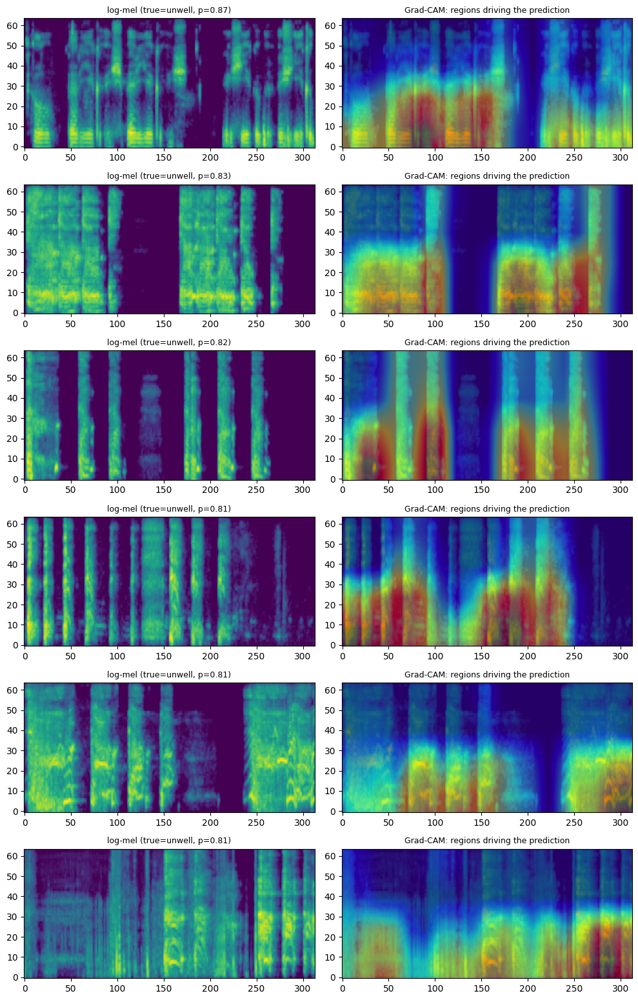

In [54]:
EPOCHS, BATCH, LR, PATIENCE = 40, 64, 1e-3, 8

Xm = {s: np.stack(Parallel(n_jobs=-1)(delayed(extract_mel)(p) for p in tqdm(parts[s]["wav_path"], desc=f"log-mel {s}")))
      for s in parts}
mean, std = float(Xm["train"].mean()), float(Xm["train"].std() + 1e-6)

mk = lambda s, aug, sh: DataLoader(SpecDataset(Xm[s], y[s], mean, std, aug), batch_size=BATCH, shuffle=sh)
train_dl, val_dl, test_dl = mk("train", True, True), mk("val", False, False), mk("test", False, False)

model = CoughCNN().to(device)
pos_weight = torch.tensor((y["train"] == 0).sum() / max((y["train"] == 1).sum(), 1),
                          dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)

best_auc, best_state, bad = -1.0, None, 0
for epoch in range(1, EPOCHS + 1):
    model.train(); total = 0.0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); opt.step()
        total += loss.item() * len(xb)
    val_auc = roc_auc_score(y["val"], predict(model, val_dl))
    sched.step(val_auc)
    print(f"epoch {epoch:02d} | loss {total/len(train_dl.dataset):.4f} | val AUC {val_auc:.4f}")
    if val_auc > best_auc:
        best_auc, bad = val_auc, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
        if bad >= PATIENCE:
            print("Early stopping."); break

model.load_state_dict(best_state)
Path("/content/results/cnn").mkdir(parents=True, exist_ok=True)
torch.save(best_state, "/content/results/cnn/cough_cnn.pt")
p_val, p_test = predict(model, val_dl), predict(model, test_dl)
results["cnn"] = report("cnn", y["val"], p_val, y["test"], p_test, "/content/results/cnn")

# Grad-CAM on the most confident true "unwell" test examples
idx = np.where(y["test"] == 1)[0]
idx = idx[np.argsort(-p_test[idx])][:6]
fig, axes = plt.subplots(len(idx), 2, figsize=(10, 2.6 * len(idx)), squeeze=False)
for r, i in enumerate(idx):
    x = torch.from_numpy((Xm["test"][i] - mean) / std).float()[None, None].to(device)
    cam = grad_cam(model, x)[0, 0].cpu().numpy()
    axes[r, 0].imshow(Xm["test"][i], origin="lower", aspect="auto")
    axes[r, 0].set_title(f"log-mel (true=unwell, p={p_test[i]:.2f})", fontsize=9)
    axes[r, 1].imshow(Xm["test"][i], origin="lower", aspect="auto")
    axes[r, 1].imshow(cam, origin="lower", aspect="auto", cmap="jet", alpha=0.45)
    axes[r, 1].set_title("Grad-CAM: regions driving the prediction", fontsize=9)
plt.tight_layout(); plt.savefig("/content/results/cnn/gradcam_examples.png", dpi=150); plt.show()

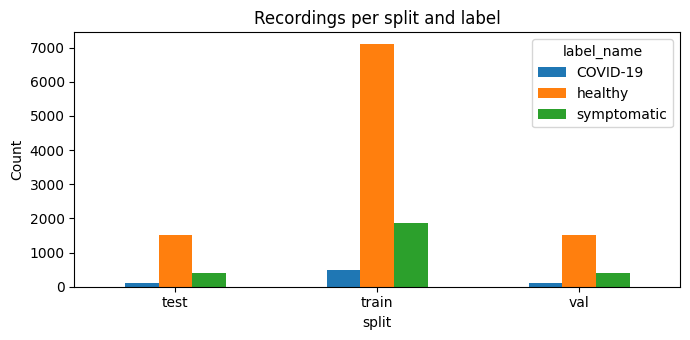

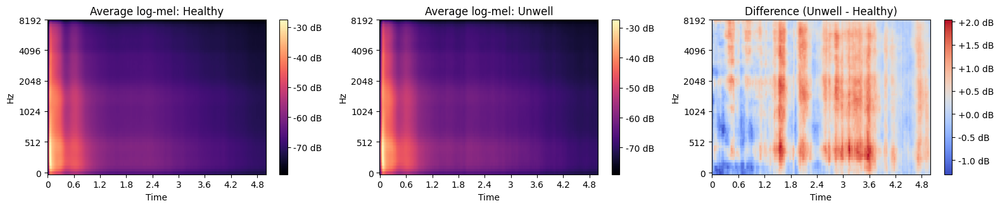

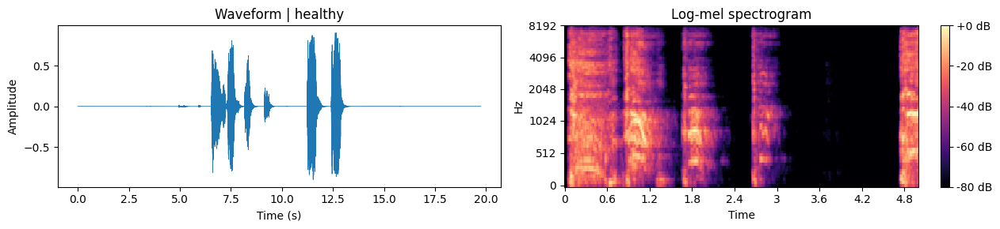

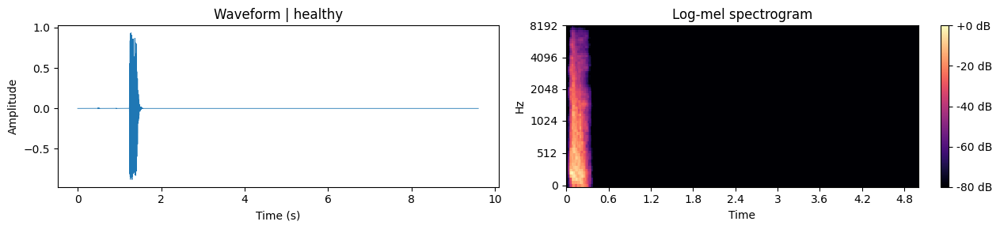

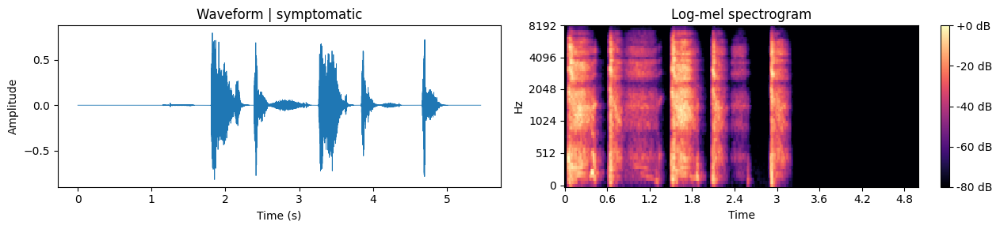

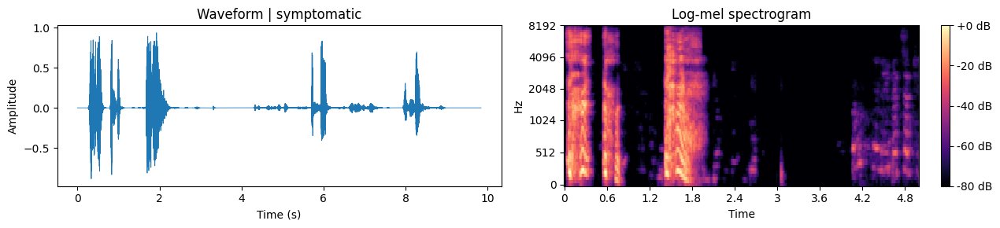

In [55]:
from IPython.display import Audio, display
import librosa.display

# 1) Class balance per split
counts = df.groupby(["split", "label_name"]).size().unstack(fill_value=0)
counts.plot(kind="bar", figsize=(7, 3.5), title="Recordings per split and label")
plt.ylabel("Count"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# 2) Average log-mel spectrogram per class (training set)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
means = {c: Xm["train"][y["train"] == c].mean(axis=0) for c in [0, 1]}
for k, (c, name) in enumerate([(0, "Healthy"), (1, "Unwell")]):
    img = librosa.display.specshow(means[c], sr=SR, hop_length=HOP, x_axis="time", y_axis="mel",
                                   fmax=SR // 2, ax=ax[k])
    ax[k].set_title(f"Average log-mel: {name}")
    fig.colorbar(img, ax=ax[k], format="%+2.0f dB")
diff = means[1] - means[0]
img = librosa.display.specshow(diff, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel",
                               fmax=SR // 2, cmap="coolwarm", ax=ax[2])
ax[2].set_title("Difference (Unwell - Healthy)")
fig.colorbar(img, ax=ax[2], format="%+.1f dB")
plt.tight_layout(); plt.show()

# 3) Example clips with waveform, spectrogram and a player
def show_clip(row):
    wav, _ = librosa.load(row["wav_path"], sr=SR)
    fig, ax = plt.subplots(1, 2, figsize=(13, 3))
    ax[0].plot(np.arange(len(wav)) / SR, wav, lw=0.6)
    ax[0].set(title=f"Waveform | {row['label_name']}", xlabel="Time (s)", ylabel="Amplitude")
    S = log_mel(load_audio(row["wav_path"]))
    img = librosa.display.specshow(S, sr=SR, hop_length=HOP, x_axis="time", y_axis="mel",
                                   fmax=SR // 2, ax=ax[1])
    ax[1].set_title("Log-mel spectrogram")
    fig.colorbar(img, ax=ax[1], format="%+2.0f dB")
    plt.tight_layout(); plt.show()
    display(Audio(row["wav_path"]))

for label in [0, 1]:
    subset = parts["train"][parts["train"]["label"] == label].sample(2, random_state=SEED)
    for _, r in subset.iterrows():
        show_clip(r)

,AUC,AUC 95% CI,sensitivity,specificity,F1,balanced acc
model,,,,,,
svm,0.585,0.555-0.612,0.321,0.787,0.329,0.554
random_forest,0.579,0.549-0.608,0.521,0.593,0.381,0.557
cnn,0.598,0.568-0.624,0.599,0.530,0.399,0.564


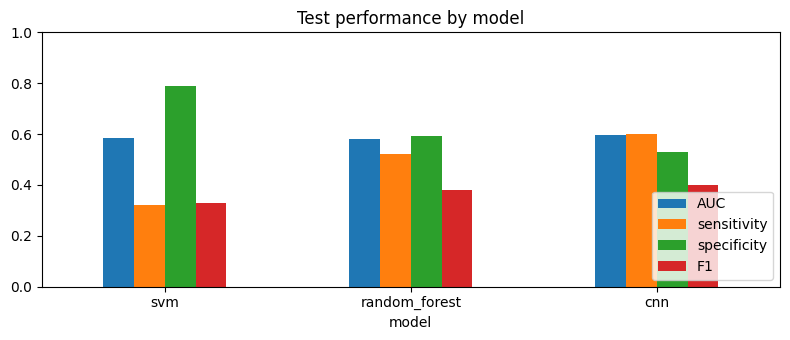

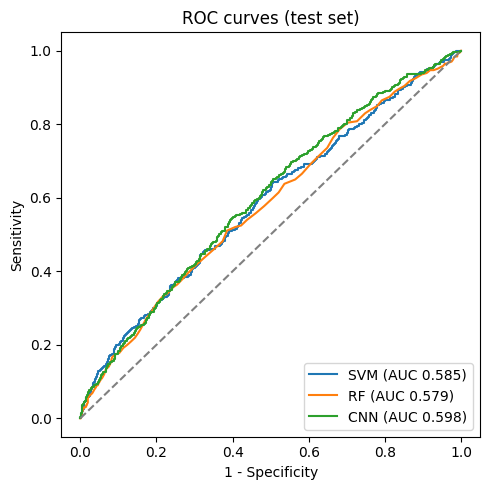

In [56]:
rows = []
for name, r in results.items():
    m = r["test_at_val_threshold"]
    rows.append({"model": name, "AUC": m["roc_auc"], "AUC 95% CI": f"{r['test_auc_95ci'][0]:.3f}-{r['test_auc_95ci'][1]:.3f}",
                 "sensitivity": m["sensitivity_recall"], "specificity": m["specificity"],
                 "F1": m["f1"], "balanced acc": m["balanced_accuracy"]})
summary = pd.DataFrame(rows).set_index("model")
display(summary.round(3))

summary[["AUC", "sensitivity", "specificity", "F1"]].plot(kind="bar", figsize=(8, 3.5), ylim=(0, 1),
                                                           title="Test performance by model")
plt.xticks(rotation=0); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

# Overlay ROC curves
p_val_all = {"SVM": svm.predict_proba(Xh["val"])[:, 1], "RF": rf.predict_proba(Xh["val"])[:, 1], "CNN": p_val}
p_test_all = {"SVM": svm.predict_proba(Xh["test"])[:, 1], "RF": rf.predict_proba(Xh["test"])[:, 1], "CNN": p_test}
thr = {k: youden_threshold(y["val"], v) for k, v in p_val_all.items()}   # thresholds chosen on validation only

plt.figure(figsize=(5, 5))
for k, p in p_test_all.items():
    fpr, tpr, _ = roc_curve(y["test"], p)
    plt.plot(fpr, tpr, label=f"{k} (AUC {roc_auc_score(y['test'], p):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("1 - Specificity"); plt.ylabel("Sensitivity"); plt.title("ROC curves (test set)")
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

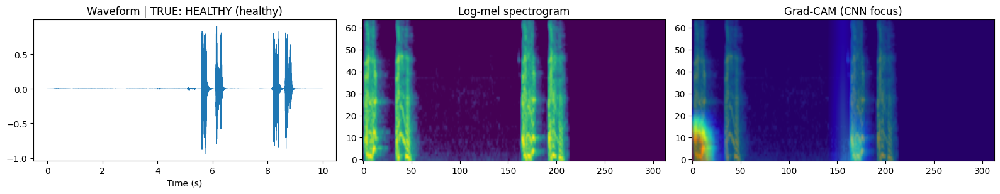

  SVM  P(unwell)=0.22 -> HEALTHY ✓ correct
  RF   P(unwell)=0.18 -> HEALTHY ✓ correct
  CNN  P(unwell)=0.40 -> HEALTHY ✓ correct


--------------------------------------------------------------------------------


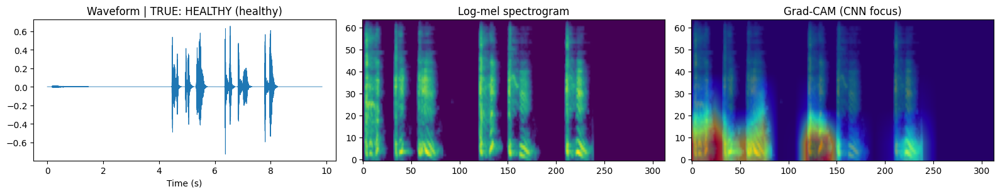

  SVM  P(unwell)=0.33 -> UNWELL  ✗ wrong
  RF   P(unwell)=0.24 -> HEALTHY ✓ correct
  CNN  P(unwell)=0.47 -> HEALTHY ✓ correct


--------------------------------------------------------------------------------


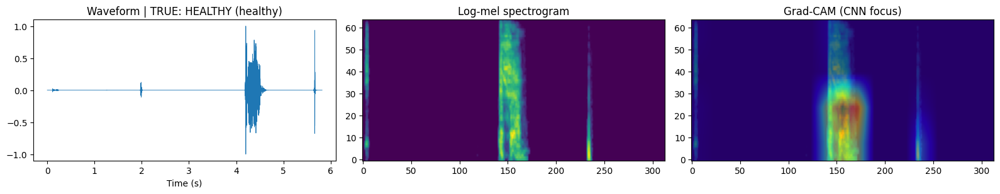

  SVM  P(unwell)=0.24 -> HEALTHY ✓ correct
  RF   P(unwell)=0.23 -> HEALTHY ✓ correct
  CNN  P(unwell)=0.49 -> HEALTHY ✓ correct


--------------------------------------------------------------------------------


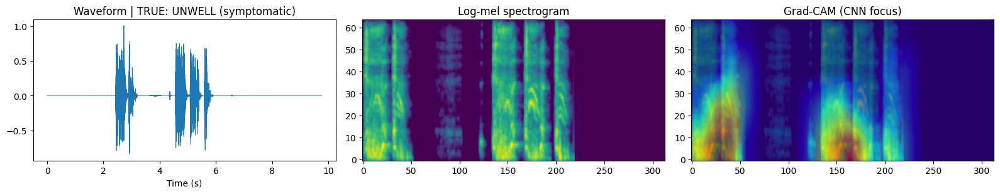

  SVM  P(unwell)=0.35 -> UNWELL  ✓ correct
  RF   P(unwell)=0.28 -> UNWELL  ✓ correct
  CNN  P(unwell)=0.56 -> UNWELL  ✓ correct


--------------------------------------------------------------------------------


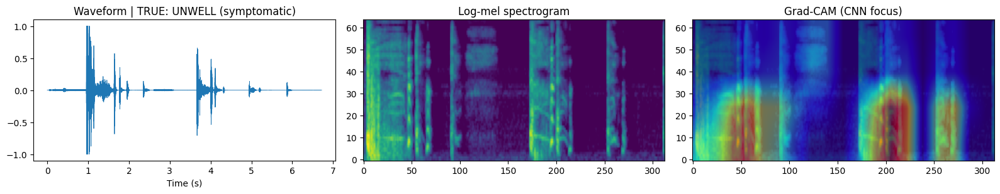

  SVM  P(unwell)=0.34 -> UNWELL  ✓ correct
  RF   P(unwell)=0.35 -> UNWELL  ✓ correct
  CNN  P(unwell)=0.73 -> UNWELL  ✓ correct


--------------------------------------------------------------------------------


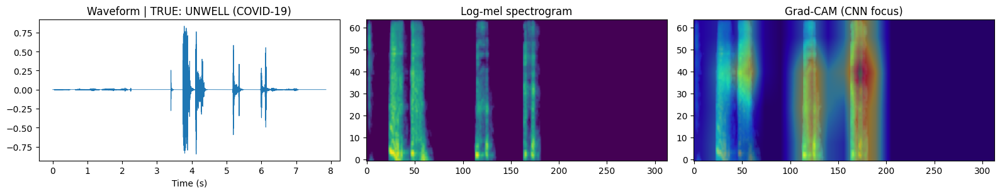

  SVM  P(unwell)=0.15 -> HEALTHY ✗ wrong
  RF   P(unwell)=0.22 -> HEALTHY ✗ wrong
  CNN  P(unwell)=0.63 -> UNWELL  ✓ correct


--------------------------------------------------------------------------------


In [57]:
def explain_sample(i):
    row = parts["test"].iloc[i]
    true = int(y["test"][i])
    wav, _ = librosa.load(row["wav_path"], sr=SR)
    x = torch.from_numpy((Xm["test"][i] - mean) / std).float()[None, None].to(device)
    cam = grad_cam(model, x)[0, 0].cpu().numpy()

    fig, ax = plt.subplots(1, 3, figsize=(16, 3.2))
    ax[0].plot(np.arange(len(wav)) / SR, wav, lw=0.6)
    ax[0].set(title=f"Waveform | TRUE: {'UNWELL' if true else 'HEALTHY'} ({row['label_name']})", xlabel="Time (s)")
    ax[1].imshow(Xm["test"][i], origin="lower", aspect="auto"); ax[1].set_title("Log-mel spectrogram")
    ax[2].imshow(Xm["test"][i], origin="lower", aspect="auto")
    ax[2].imshow(cam, origin="lower", aspect="auto", cmap="jet", alpha=0.45)
    ax[2].set_title("Grad-CAM (CNN focus)")
    plt.tight_layout(); plt.show()

    for k in ["SVM", "RF", "CNN"]:
        p = p_test_all[k][i]
        pred = int(p >= thr[k])
        print(f"  {k:4s} P(unwell)={p:.2f} -> {'UNWELL ' if pred else 'HEALTHY'} {'✓ correct' if pred == true else '✗ wrong'}")
    display(Audio(row["wav_path"]))
    print("-" * 80)

rng = np.random.default_rng(0)
picked = []
for c in [0, 1]:
    pool = np.where(y["test"] == c)[0]
    picked += list(rng.choice(pool, size=min(3, len(pool)), replace=False))

for i in picked:
    explain_sample(int(i))

False negatives (missed unwell): 205 | False positives (false alarms): 715

=== Most confident MISSED cases ===


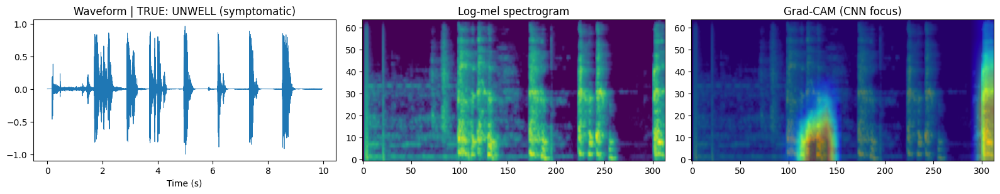

  SVM  P(unwell)=0.18 -> HEALTHY ✗ wrong
  RF   P(unwell)=0.25 -> HEALTHY ✗ wrong
  CNN  P(unwell)=0.32 -> HEALTHY ✗ wrong


--------------------------------------------------------------------------------


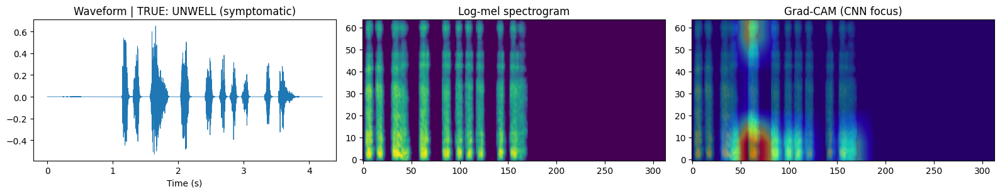

  SVM  P(unwell)=0.20 -> HEALTHY ✗ wrong
  RF   P(unwell)=0.22 -> HEALTHY ✗ wrong
  CNN  P(unwell)=0.32 -> HEALTHY ✗ wrong


--------------------------------------------------------------------------------


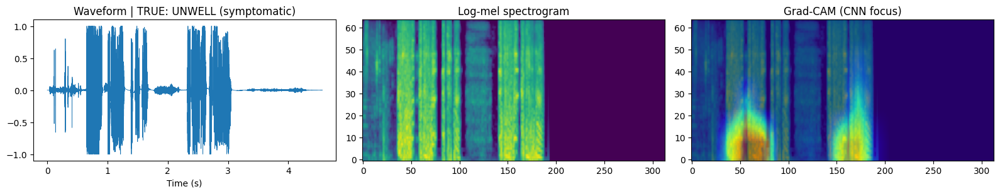

  SVM  P(unwell)=0.21 -> HEALTHY ✗ wrong
  RF   P(unwell)=0.21 -> HEALTHY ✗ wrong
  CNN  P(unwell)=0.37 -> HEALTHY ✗ wrong


--------------------------------------------------------------------------------

=== Most confident FALSE ALARMS ===


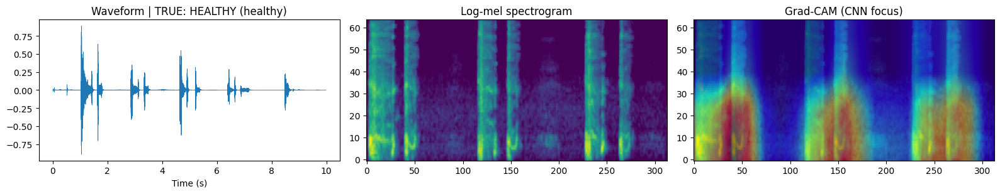

  SVM  P(unwell)=0.38 -> UNWELL  ✗ wrong
  RF   P(unwell)=0.37 -> UNWELL  ✗ wrong
  CNN  P(unwell)=0.83 -> UNWELL  ✗ wrong


--------------------------------------------------------------------------------


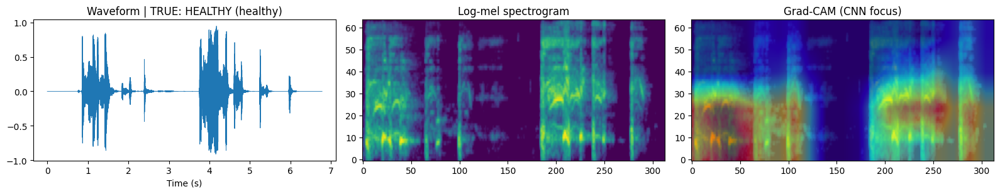

  SVM  P(unwell)=0.32 -> UNWELL  ✗ wrong
  RF   P(unwell)=0.28 -> UNWELL  ✗ wrong
  CNN  P(unwell)=0.81 -> UNWELL  ✗ wrong


--------------------------------------------------------------------------------


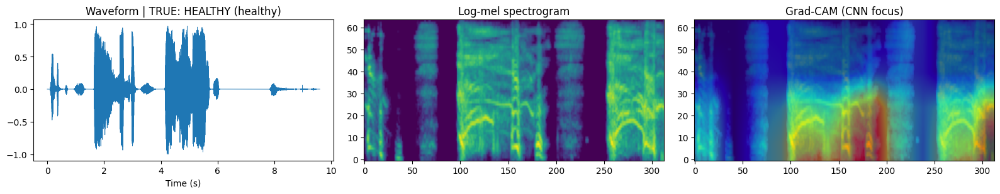

  SVM  P(unwell)=0.33 -> UNWELL  ✗ wrong
  RF   P(unwell)=0.26 -> UNWELL  ✗ wrong
  CNN  P(unwell)=0.80 -> UNWELL  ✗ wrong


--------------------------------------------------------------------------------


In [58]:
pred_cnn = (p_test_all["CNN"] >= thr["CNN"]).astype(int)

fn = np.where((y["test"] == 1) & (pred_cnn == 0))[0]   # missed unwell
fp = np.where((y["test"] == 0) & (pred_cnn == 1))[0]   # false alarms
print(f"False negatives (missed unwell): {len(fn)} | False positives (false alarms): {len(fp)}")

print("\n=== Most confident MISSED cases ===")
for i in fn[np.argsort(p_test_all["CNN"][fn])][:3]:
    explain_sample(int(i))

print("\n=== Most confident FALSE ALARMS ===")
for i in fp[np.argsort(-p_test_all["CNN"][fp])][:3]:
    explain_sample(int(i))

Upload a short cough recording (wav, mp3, m4a, ogg, webm)


Saving WhatsApp Ptt 2026-11-24 at 10.37.25 PM.ogg to WhatsApp Ptt 2026-11-24 at 10.37.25 PM (1).ogg


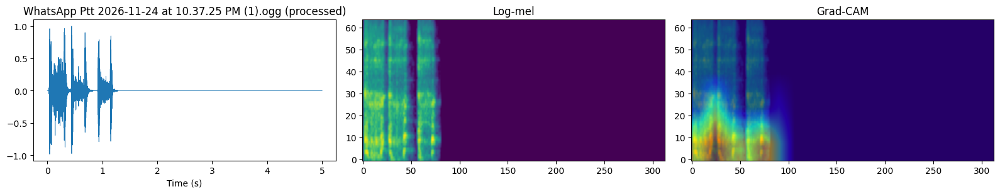

SVM  P(unwell)=0.24 -> HEALTHY
RF   P(unwell)=0.22 -> HEALTHY
CNN  P(unwell)=0.47 -> HEALTHY


Demo only: this is a research prototype, not a medical test.


In [59]:
from google.colab import files

print("Upload a short cough recording (wav, mp3, m4a, ogg, webm)")
uploaded = files.upload()

for fname in uploaded:
    wav_path = f"/content/{Path(fname).stem}_16k.wav"
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", fname, "-ac", "1", "-ar", str(SR), wav_path])

    y_ = load_audio(wav_path)
    p = {"SVM": svm.predict_proba(handcrafted_features(y_)[None])[0, 1],
         "RF": rf.predict_proba(handcrafted_features(y_)[None])[0, 1]}
    spec = log_mel(y_)
    x = torch.from_numpy((spec - mean) / std).float()[None, None].to(device)
    model.eval()
    with torch.no_grad():
        p["CNN"] = torch.sigmoid(model(x)).item()
    cam = grad_cam(model, x)[0, 0].cpu().numpy()

    fig, ax = plt.subplots(1, 3, figsize=(16, 3.2))
    ax[0].plot(np.arange(len(y_)) / SR, y_, lw=0.6); ax[0].set(title=f"{fname} (processed)", xlabel="Time (s)")
    ax[1].imshow(spec, origin="lower", aspect="auto"); ax[1].set_title("Log-mel")
    ax[2].imshow(spec, origin="lower", aspect="auto"); ax[2].imshow(cam, origin="lower", aspect="auto", cmap="jet", alpha=0.45)
    ax[2].set_title("Grad-CAM")
    plt.tight_layout(); plt.show()

    for k, v in p.items():
        print(f"{k:4s} P(unwell)={v:.2f} -> {'UNWELL' if v >= thr[k] else 'HEALTHY'}")
    display(Audio(wav_path))
    print("Demo only: this is a research prototype, not a medical test.")

                 AUC   AUC 95% CI  sensitivity  specificity
model                                                      
svm            0.585  0.555-0.612        0.321        0.787
random_forest  0.579  0.549-0.608        0.521        0.593
cnn            0.598  0.568-0.624        0.599        0.530


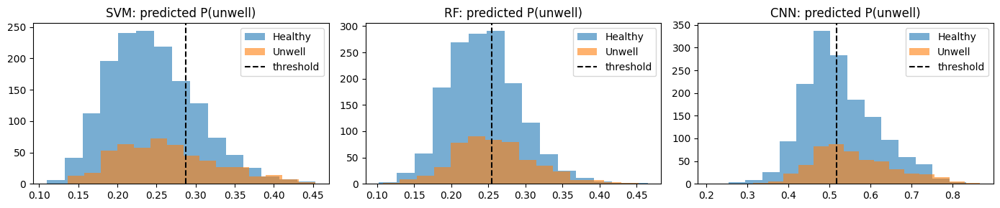

In [60]:
print(summary[["AUC", "AUC 95% CI", "sensitivity", "specificity"]].round(3))

fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a, (k, p) in zip(ax, p_test_all.items()):
    a.hist(p[y["test"] == 0], bins=15, alpha=0.6, label="Healthy")
    a.hist(p[y["test"] == 1], bins=15, alpha=0.6, label="Unwell")
    a.axvline(thr[k], color="k", ls="--", label="threshold")
    a.set_title(f"{k}: predicted P(unwell)"); a.legend()
plt.tight_layout(); plt.show()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.weight     | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.dense.bias       | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


AST embeddings:   0%|          | 0/593 [00:00<?, ?it/s]

AST embeddings:   0%|          | 0/127 [00:00<?, ?it/s]

AST embeddings:   0%|          | 0/127 [00:00<?, ?it/s]

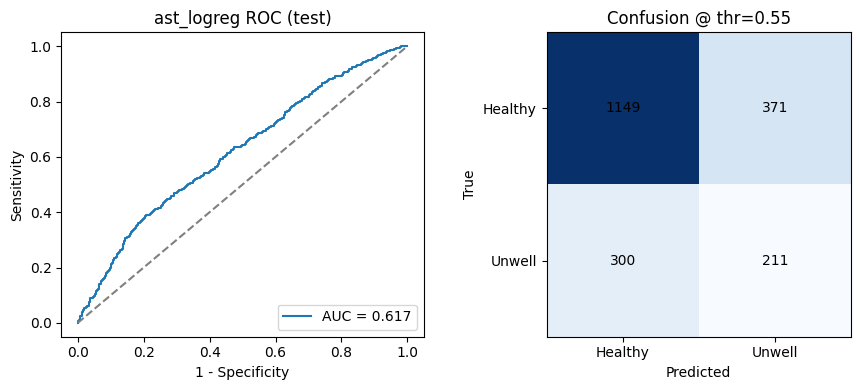

[ast_logreg] test AUC 0.617 (95% CI 0.588-0.643) | sensitivity 0.413 | specificity 0.756 | F1 0.386 | threshold 0.549


In [61]:
!pip -q install transformers
from transformers import ASTFeatureExtractor, ASTModel
from sklearn.linear_model import LogisticRegression

name = "MIT/ast-finetuned-audioset-10-10-0.4593"
fe = ASTFeatureExtractor.from_pretrained(name)
ast = ASTModel.from_pretrained(name).to(device).eval()

@torch.no_grad()
def embed(paths, bs=16):
    out = []
    for i in tqdm(range(0, len(paths), bs), desc="AST embeddings"):
        wavs = [load_audio(p) for p in paths[i:i + bs]]
        inp = fe(wavs, sampling_rate=SR, return_tensors="pt").to(device)
        out.append(ast(**inp).pooler_output.cpu().numpy())
    return np.vstack(out)

Xe = {s: embed(list(parts[s]["wav_path"])) for s in parts}

lr = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    {"logisticregression__C": [0.001, 0.01, 0.1, 1]},
    scoring="roc_auc", cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=-1,
).fit(Xe["train"], y["train"])

results["ast_logreg"] = report("ast_logreg", y["val"], lr.predict_proba(Xe["val"])[:, 1],
                               y["test"], lr.predict_proba(Xe["test"])[:, 1], "/content/results/ast")

In [62]:
from sklearn.linear_model import LogisticRegression

g = {s: parts[s]["gender"].isin(["male", "female"]).values for s in parts}
yg = {s: (parts[s]["gender"][g[s]] == "female").astype(int).values for s in parts}

clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced"))
clf.fit(Xh["train"][g["train"]], yg["train"])
p = clf.predict_proba(Xh["test"][g["test"]])[:, 1]
print("Gender AUC from cough audio:", round(roc_auc_score(yg["test"], p), 3),
      "| n test =", len(yg["test"]))

Gender AUC from cough audio: 0.815 | n test = 2016


In [63]:
import soundfile as sf

t = parts["test"].copy()
t["y"] = y["test"]
t["p_cnn"] = p_test_all["CNN"]
t["pred"] = (t["p_cnn"] >= thr["CNN"]).astype(int)
t["dur"] = [sf.info(p).duration for p in t["wav_path"]]

print("Test prevalence of unwell:", round(t["y"].mean(), 3), "| n =", len(t))
print(pd.crosstab(t["y"], t["pred"], margins=True))

cols = [c for c in ["SNR", "cough_detected", "age", "dur"] if c in t.columns]
print("\nMean recording traits by (true label, CNN prediction):")
print(t.groupby(["y", "pred"])[cols].mean().round(2))

print("\nShare predicted unwell, by gender:")
print(pd.crosstab(t["gender"], t["pred"], normalize="index").round(2))

Test prevalence of unwell: 0.252 | n = 2031
pred     0     1   All
y                     
0      805   715  1520
1      205   306   511
All   1010  1021  2031

Mean recording traits by (true label, CNN prediction):
        cough_detected    age   dur
y pred                             
0 0               0.95  36.79  8.00
  1               0.96  37.93  8.43
1 0               0.95  35.03  7.96
  1               0.95  36.11  8.47

Share predicted unwell, by gender:
pred       0     1
gender            
female  0.41  0.59
male    0.55  0.45
other   0.60  0.40


In [62]:
print(pd.crosstab(df["gender"], df["label_name"], normalize="index").round(2))
print(df.groupby("label_name")["age"].describe().round(1))